# Modellierung

## Init

In [84]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df.index = pd.to_datetime(df.index)

# Datenselektierung

In [85]:
display(df.head())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,tavg,tmin,tmax,unix_ts_date,needed_personal,calls_per_duty,call_stress,sby_used_percent
date,,,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,False,8.3,5.0,13.1,1459468800,1631.0,4.796471,4.785211,4.444444
2016-04-02,64,8526.0,1700,90,70.0,0.0,False,9.9,1.3,16.4,1459555200,1706.0,5.015294,4.816949,77.777778
2016-04-03,68,8088.0,1700,90,0.0,0.0,False,13.1,6.1,19.1,1459641600,1632.0,4.757647,4.757647,0.000000
2016-04-04,71,7044.0,1700,90,0.0,0.0,False,15.2,9.5,20.6,1459728000,1629.0,4.143529,4.143529,0.000000
2016-04-05,63,7236.0,1700,90,0.0,0.0,False,16.0,8.4,22.7,1459814400,1637.0,4.256471,4.256471,0.000000


In [86]:
print(df.columns)

Index(['n_sick', 'calls', 'n_duty', 'n_sby', 'sby_need', 'dafted',
       'is_holiday', 'tavg', 'tmin', 'tmax', 'unix_ts_date', 'needed_personal',
       'calls_per_duty', 'call_stress', 'sby_used_percent'],
      dtype='object')


In [87]:

# List der Spalten, die nicht benutzt werden sollen, da sie u. a. zur Anwendungszeit nicht zur Verfügung stehen und daher auch nicht als Features genutzt werden können oder
excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "needed_personal"]

usable_columns = list(set(df.columns) - set(excluded_columns))

#Overwrite usable_columns to force certain scenario
#usable_columns = ["unix_ts_date"]                                                                                               # R2: 44% (this and all below only works for shuffled data)
#usable_columns = ["unix_ts_date", "year", "month", "week_of_year", "day_of_year", "is_weekend", "is_holiday", "day_of_week"]           # R2: 51,1% 
#usable_columns = ["month", "day_of_year"]                                                                                      # R2: 22%
#usable_columns = ["year", "day_of_year"]                                                                                       # R2: 44%
#usable_columns = ["unix_ts_date", "month"]                                                                                     # R2: 45%
#usable_columns = ["unix_ts_date", "month", "day_of_year"]                                                                      # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend"]                                                                                 # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend", "is_holiday", "day_of_week", "month"]                                                                   # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend", "calls_ma_7_lag_30"]                                                                   # R2: 
#usable_columns = ["calls_ma_8_lag_1", "unix_ts_date"]
#usable_columns = ["week_of_year", "day_of_week", "is_holiday", "is_weekend"]

target_column = 'sby_need'

print("Usable columns:", usable_columns)

Usable columns: ['n_sby', 'tmax', 'n_duty', 'is_holiday', 'unix_ts_date', 'tavg', 'tmin']


In [103]:
from sklearn.model_selection import train_test_split


# Prepare features and target
X = df[usable_columns]

#X = df[['n_duty', 'season', 'month', 'day_of_week', 'is_holiday', 'is_weekend']] #auf faktoren beschränkt, die man zu dem Zeitpunkt der Planung wissen kann

y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False) # shuffle = False um Daten Ordnung beizubehalten

# Modellierungvergleiche

In [104]:
# Modelle für Nutzung

from sklearn.ensemble import StackingRegressor, RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import BaggingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Zusätzliche Modelle, die nicht aus sklearn stammen
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [105]:
models = {
    # 'StackingRegressor': StackingRegressor(
    #     estimators=[
    #         ('lr', LinearRegression()),
    #         ('dt', DecisionTreeRegressor(max_depth=10, min_samples_split=10, min_samples_leaf=5)),
    #         ('svr', SVR(C=10, kernel='rbf', gamma='scale'))
    #     ],
    #     final_estimator=Ridge(alpha=1.0),
    #     cv=5,
    #     n_jobs=-1
    # ),
    
    # 'StackingRegressor_2': StackingRegressor(
    #     estimators=[
    #         ('gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)),
    #         ('nn', MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1500, random_state=42)),
    #         ('knn', KNeighborsRegressor(n_neighbors=7, weights='distance', p=2))
    #     ],
    #     final_estimator=Ridge(alpha=1.0),
    #     cv=5,
    #     n_jobs=-1
    # ),
    
    'Linear Regression': LinearRegression(),
    
    # 'Decision Tree': DecisionTreeRegressor(
    #     max_depth=10, 
    #     min_samples_split=10, 
    #     min_samples_leaf=5, 
    #     random_state=42
    # ),
    
    'Random Forest': RandomForestRegressor(
        #n_estimators=200, 
        #max_depth=10, 
        #min_samples_split=10, 
        #min_samples_leaf=5, 
        #bootstrap=True, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #random_state=42
    ),
    
    # 'Support Vector Machine': SVR(
    #     C=10, 
    #     kernel='rbf', 
    #     gamma='scale'
    # ),
    
    #'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=7, weights='distance', p=2),
    
    'Lasso Regression': Lasso(
        alpha=0.01, 
        max_iter=1000, 
        random_state=42
    ),
    
    'Ridge Regression': Ridge(
        alpha=1.0, 
        random_state=42
    ),
    
    'XGBoost': XGBRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #colsample_bytree=0.8, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    # Polynomial Regression
    'Polynomial Regression (10)': Pipeline([
        ('poly', PolynomialFeatures(degree=10)),
        ('linear', LinearRegression())
    ]),
    
    'Polynomial Ridge Regression (10)': Pipeline([
        ('poly', PolynomialFeatures(degree=10)),
        ('ridge', Ridge(alpha=1.0))
    ]),

    'Polynomial Lasso Regression (10)': Pipeline([
        ('poly', PolynomialFeatures(degree=10)),
        ('lasso', Lasso(alpha=0.01, max_iter=1000, random_state=42))
    ]),

    'LightGBM': LGBMRegressor(
        n_estimators=200, 
        learning_rate=0.05, 
        num_leaves=31, 
        max_depth=-1, 
        min_child_samples=20, 
        subsample=0.8, 
        colsample_bytree=0.8, 
        random_state=42
    ),
    # 'Bagging Regressor': BaggingRegressor(
    #     n_estimators=50,
    #     random_state=42,
    #     n_jobs=-1
    # ),
    
    # 'HistGradient Boosting': HistGradientBoostingRegressor(
    #     loss='absolute_error',
    #     learning_rate=0.05,
    #     max_iter=100,
    #     max_depth=4,
    #     random_state=42
    # )
}


In [106]:
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.preprocessing import MinMaxScaler

# Flag to enable or disable MinMaxScaler
use_scaler = False

# Initialize the scaler
scaler = MinMaxScaler()

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    # Apply MinMaxScaler if the flag is set
    if use_scaler:
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
    else:
        X_train_scaled = X_train
        X_test_scaled = X_test

    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "MAPE" : mape, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "MAPE" : {mape}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 50.123568604544026, MSE: 5583.890596236321, RMSE: 74.72543473434143, R2: 0.008157903106106645, "MAPE" : 1.1703874865225547e+17, "Training Time (s)" : 0.0023109912872314453
Random Forest - MAE: 47.65367965367965, MSE: 5892.38974891775, RMSE: 76.76190297874167, R2: -0.04663945390009561, "MAPE" : 1.0696322060436888e+17, "Training Time (s)" : 0.2850322723388672
Gradient Boosting - MAE: 46.597488940279746, MSE: 5765.836642376734, RMSE: 75.93310636591087, R2: -0.02416037835289897, "MAPE" : 1.0293727867700834e+17, "Training Time (s)" : 0.10735893249511719
Lasso Regression - MAE: 50.11933759741961, MSE: 5582.585256944702, RMSE: 74.71669998698218, R2: 0.008389764822922752, "MAPE" : 1.1703329566512106e+17, "Training Time (s)" : 0.015258312225341797
Ridge Regression - MAE: 50.11987638871498, MSE: 5582.100890832621, RMSE: 74.71345856559326, R2: 0.008475800659762944, "MAPE" : 1.1703960464333227e+17, "Training Time (s)" : 0.0013921260833740234
XGBoost - MAE: 48.3202556476513

/usr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.769e+06, tolerance: 6.008e+02
  model = cd_fast.enet_coordinate_descent(
/usr/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=1.34713e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Polynomial Regression (10) - MAE: 49.34612340376243, MSE: 5305.150335102074, RMSE: 72.83646295024268, R2: 0.05766931818979193, "MAPE" : 1.1782228173417443e+17, "Training Time (s)" : 12.760300874710083


/usr/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(


Polynomial Ridge Regression (10) - MAE: 49.4114697055726, MSE: 5421.381678655744, RMSE: 73.63003245045967, R2: 0.037023652317905054, "MAPE" : 1.1210469755552154e+17, "Training Time (s)" : 9.472431182861328
Polynomial Lasso Regression (10) - MAE: 82.65204621469496, MSE: 206410.22917320146, RMSE: 454.32392538056087, R2: -35.66374743471654, "MAPE" : 2.612834610496425e+17, "Training Time (s)" : 30.12145185470581
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000103 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 950
[LightGBM] [Info] Number of data points in the train set: 921, number of used features: 6
[LightGBM] [Info] Start training from score 35.326819
LightGBM - MAE: 50.577512776014586, MSE: 6305.6703283971565, RMSE: 79.40825100955918, R2: -0.12004867807663433, "MAPE" : 1.1079113434613856e+17, "Training Time (s)" : 0.07059478759765625


/usr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.391e+06, tolerance: 6.008e+02
  model = cd_fast.enet_coordinate_descent(


In [110]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

sorted_by = 'R2'

# For R2 it has to be desending
results_df_sorted = results_df.sort_values(by=sorted_by, ascending=False)

print(f"Models sorted by {sorted_by}:")
display(results_df_sorted)

# Select the best model
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Models sorted by R2:


,MAE,MSE,RMSE,R2,MAPE,Training Time
Polynomial Regression (10),49.346123,5305.150335,72.836463,0.057669,1.178223e+17,12.760301
Polynomial Ridge Regression (10),49.411470,5421.381679,73.630032,0.037024,1.121047e+17,9.472431
Ridge Regression,50.119876,5582.100891,74.713459,0.008476,1.170396e+17,0.001392
Lasso Regression,50.119338,5582.585257,74.716700,0.008390,1.170333e+17,0.015258
Linear Regression,50.123569,5583.890596,74.725435,0.008158,1.170387e+17,0.002311
Gradient Boosting,46.597489,5765.836642,75.933106,-0.024160,1.029373e+17,0.107359
Random Forest,47.653680,5892.389749,76.761903,-0.046639,1.069632e+17,0.285032
LightGBM,50.577513,6305.670328,79.408251,-0.120049,1.107911e+17,0.070595
XGBoost,48.320256,6476.818309,80.478682,-0.150449,1.026136e+17,0.044762
Polynomial Lasso Regression (10),82.652046,206410.229173,454.323925,-35.663747,2.612835e+17,30.121452


Best Model: Polynomial Regression (10)
MAE              4.934612e+01
MSE              5.305150e+03
RMSE             7.283646e+01
R2               5.766932e-02
MAPE             1.178223e+17
Training Time    1.276030e+01
Name: Polynomial Regression (10), dtype: float64


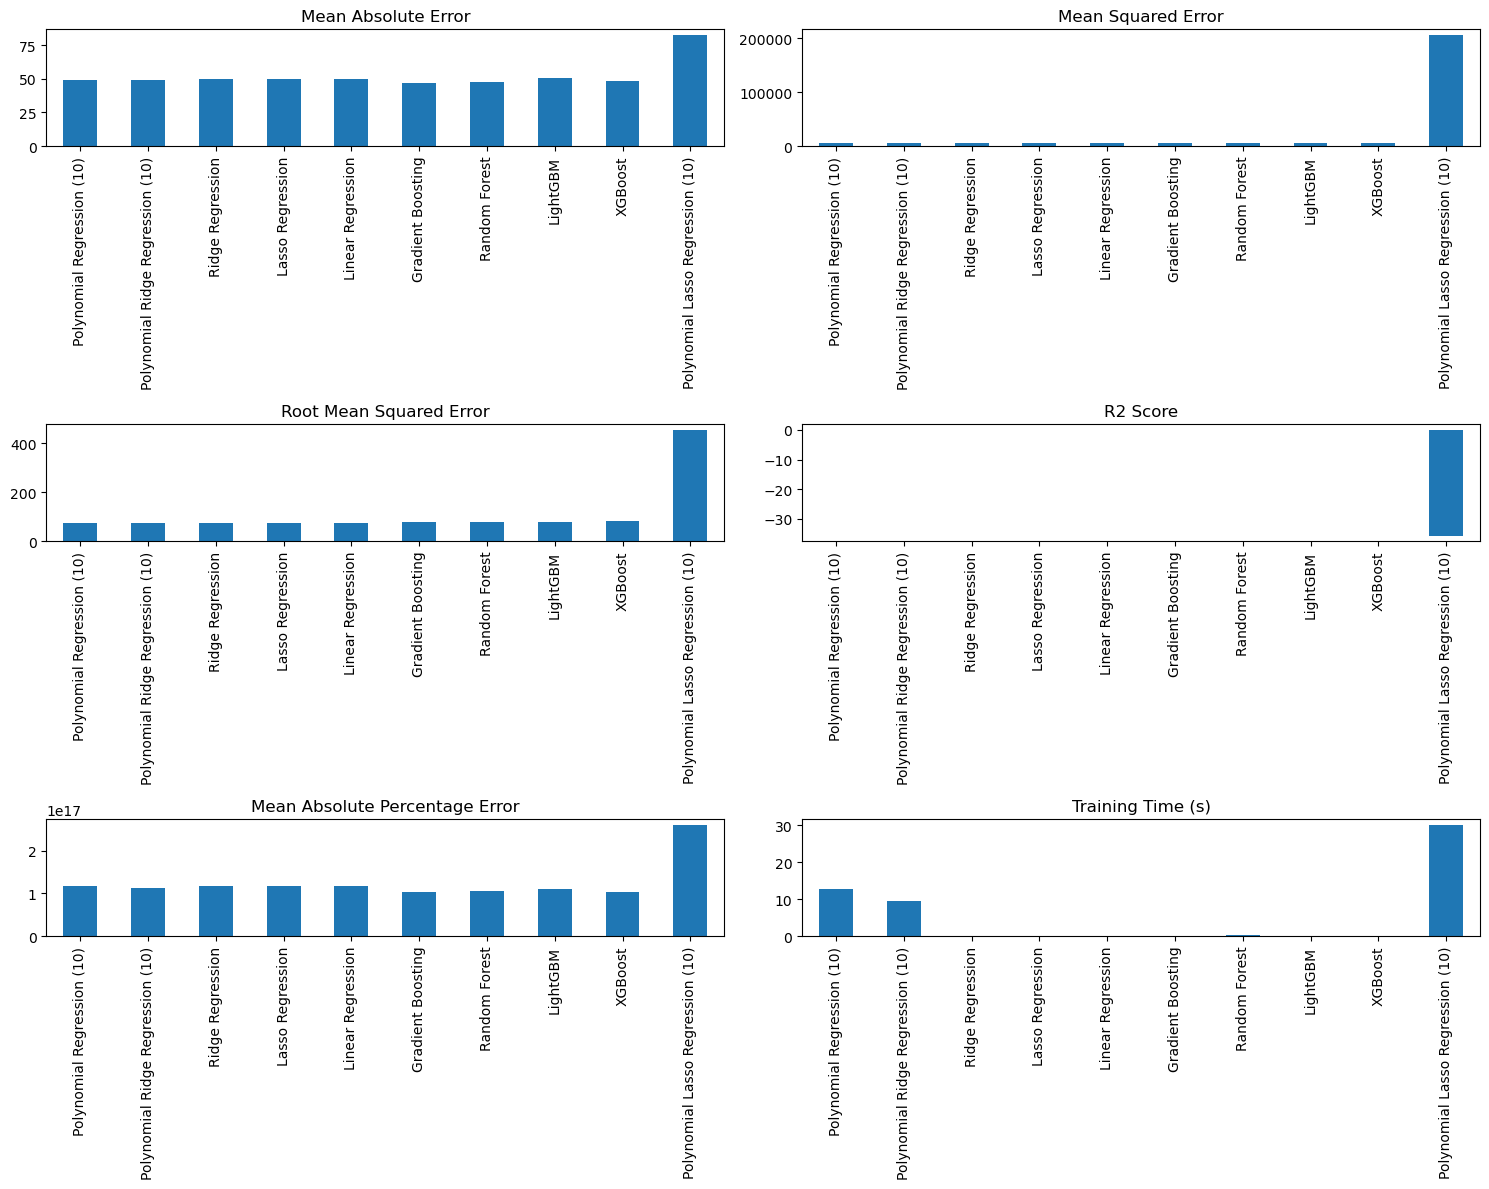

In [111]:
import matplotlib.pyplot as plt

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['MAPE'].plot(kind='bar', ax=axes[2, 0], title='Mean Absolute Percentage Error')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 1], title='Training Time (s)')
plt.tight_layout()
plt.show()

No Hyperparameter-Tuning because there is no template
Final Evaluation of the Best Model (Polynomial Regression (10)):
MAE: 49.34612340376243, MSE: 5305.150335102074, RMSE: 72.83646295024268, R2: 0.05766931818979193


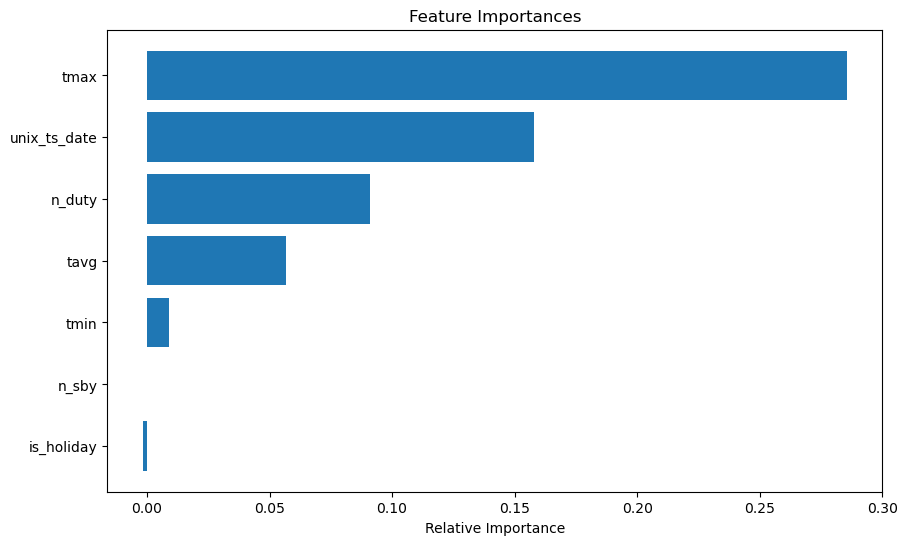

In [112]:
from sklearn.model_selection import GridSearchCV

# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

elif best_model_name == 'Lasso Regression':

    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1, 10, 100],  # Verschiedene Werte für den Regularisierungsparameter
        'max_iter': [1000, 5000, 10000],          # Maximale Anzahl an Iterationen
        'tol': [1e-4, 1e-3, 1e-2]                 # Toleranz für die Optimierung
    }

    grid_search = GridSearchCV(Lasso(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, scoring='r2', verbose=1)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

#elif best_model_name == 'StackingRegressor':
    # Do new stuff here
else:
    print("No Hyperparameter-Tuning because there is no template")
    best_model = models[best_model_name]

# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')

features = X.columns

if hasattr(best_model, "feature_importances_"):
    # Feature Importance for the best model
    importances = best_model.feature_importances_
elif hasattr(best_model, "coef_"):
    importances = np.argsort(np.abs(best_model.coef_))
else: 
    from sklearn.inspection import permutation_importance
    perm_importance = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
    importances = perm_importance.importances_mean
        

indices = np.argsort(importances)
plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

In [113]:
top_features = [features[i] for i in indices][-5:]

top_features.reverse()

display(top_features)

['tmax', 'unix_ts_date', 'n_duty', 'tavg', 'tmin']

# Modell mit weniger Features (nur die wichtigsten)

In [114]:
additional_columns = ["n_sick", "sby_need", "n_sby", "n_duty"]

X = df[top_features + additional_columns ]
y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

best_model.fit(X_train[top_features], y_train)

y_pred_best = best_model.predict(X_test[top_features])

mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)
mape = mean_absolute_percentage_error(y_test, y_pred_best)

print(f'MAPE: {mape}, MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')

MAPE: 1.3232275675961339e+17, MAE: 68.44232861684647, MSE: 10523.740933608784, RMSE: 102.58528614576646, R2: 0.0691266669355537


In [115]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor  # Beispielmodell

additional_columns = ["n_sick", "sby_need", "n_sby", "n_duty"]

X = df[top_features + additional_columns]
y = df[target_column]

# Daten in Trainings- und Testsets aufteilen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Beispielmodell (RandomForestRegressor)
best_model = RandomForestRegressor()
best_model.fit(X_train[top_features], y_train)

y_pred_best = best_model.predict(X_test[top_features])

# Benutzerdefinierte Verlustfunktion anwenden
def custom_loss(y_true, y_pred):
    loss = np.where(y_true > y_pred, 
                    (y_true - y_pred) ** 2 * 3,  # Straffaktor für Unterschätzungen
                    (y_true - y_pred) ** 2)
    return np.mean(loss)

# Berechnung der benutzerdefinierten Verlustfunktion
loss = custom_loss(y_test.values, y_pred_best)
print(f'Custom Loss: {loss}')

# Standardmetriken berechnen
mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)
mape = mean_absolute_percentage_error(y_test, y_pred_best)

print(f'MAPE: {mape}, MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')


Custom Loss: 26566.607041991345
MAPE: 2.4634066086443555e+17, MAE: 90.62705627705627, MSE: 12039.276412554114, RMSE: 109.72363652629325, R2: -0.06492942315288608


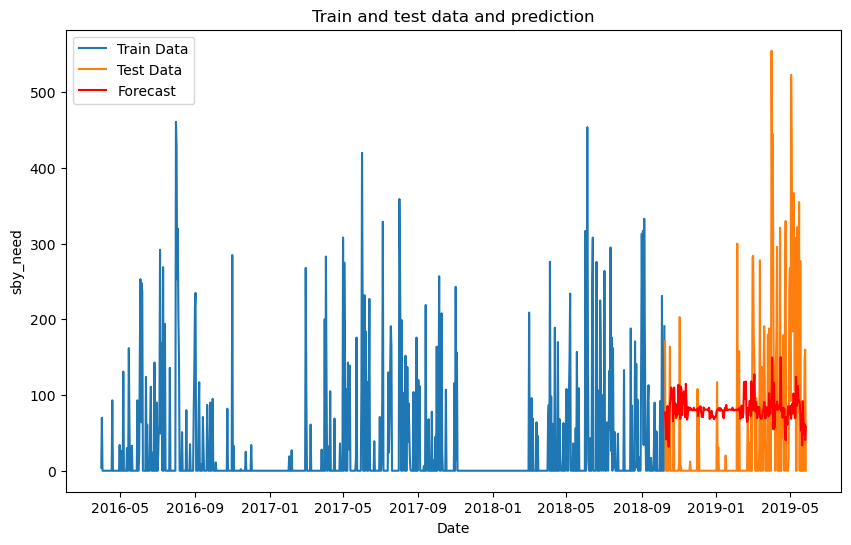

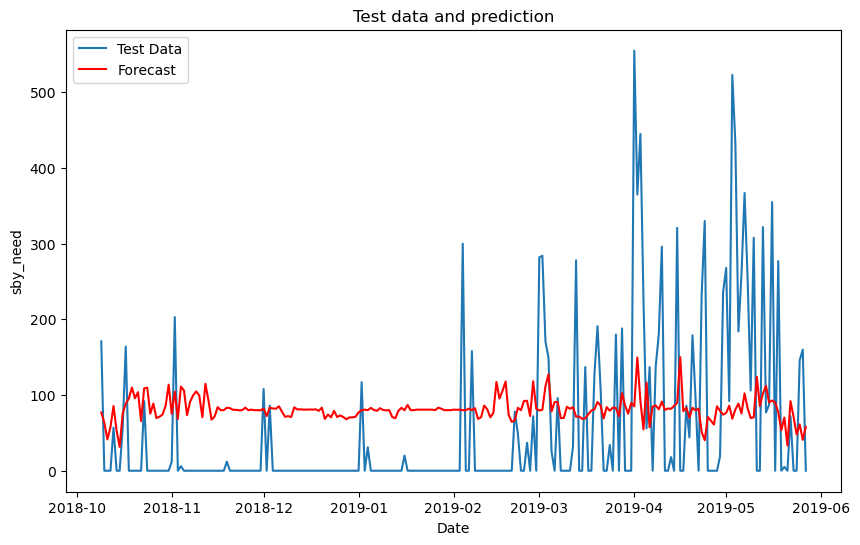

In [116]:
plt.figure(figsize=(10, 6))
plt.plot(X_train.index, y_train, label='Train Data')
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, y_pred_best, label='Forecast', color='red')
plt.title('Train and test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, y_pred_best, label='Forecast', color='red')
plt.title('Test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

# Prediction Test

In [117]:
validation_df = pd.merge(X_test, y_test, left_index=True, right_index=True)

validation_df = validation_df.rename(columns={target_column : "orig_" + target_column})

display(validation_df)

,tmax,unix_ts_date,n_duty,tavg,tmin,n_sick,sby_need_x,n_sby,n_duty,sby_need_y
date,,,,,,,,,,
2018-10-09,18.9,1539043200,1900,11.4,4.0,97,171.0,90,1900,171.0
2018-10-10,23.7,1539129600,1900,15.5,7.4,97,0.0,90,1900,0.0
2018-10-11,24.3,1539216000,1900,17.5,11.6,103,0.0,90,1900,0.0
2018-10-12,25.7,1539302400,1900,17.7,11.6,106,0.0,90,1900,0.0
2018-10-13,25.5,1539388800,1900,17.4,10.1,93,57.0,90,1900,57.0
...,...,...,...,...,...,...,...,...,...,...
2019-05-23,19.3,1558569600,1900,14.2,8.4,86,0.0,90,1900,0.0
2019-05-24,23.8,1558656000,1900,18.0,10.6,81,0.0,90,1900,0.0
2019-05-25,16.3,1558742400,1900,13.8,10.9,76,146.0,90,1900,146.0


In [118]:
validation_df[target_column] = best_model.predict(validation_df[top_features])
display(validation_df)

,tmax,unix_ts_date,n_duty,tavg,tmin,n_sick,sby_need_x,n_sby,n_duty,sby_need_y,sby_need
date,,,,,,,,,,,
2018-10-09,18.9,1539043200,1900,11.4,4.0,97,171.0,90,1900,171.0,76.92
2018-10-10,23.7,1539129600,1900,15.5,7.4,97,0.0,90,1900,0.0,63.40
2018-10-11,24.3,1539216000,1900,17.5,11.6,103,0.0,90,1900,0.0,41.32
2018-10-12,25.7,1539302400,1900,17.7,11.6,106,0.0,90,1900,0.0,57.68
2018-10-13,25.5,1539388800,1900,17.4,10.1,93,57.0,90,1900,57.0,85.48
...,...,...,...,...,...,...,...,...,...,...,...
2019-05-23,19.3,1558569600,1900,14.2,8.4,86,0.0,90,1900,0.0,71.33
2019-05-24,23.8,1558656000,1900,18.0,10.6,81,0.0,90,1900,0.0,47.82
2019-05-25,16.3,1558742400,1900,13.8,10.9,76,146.0,90,1900,146.0,61.29


# Berechnen von n_sby aus Calls

In [119]:
validation_df = validation_df.rename(columns={"sby_need" : "orig_sby_need"})

In [120]:
validation_df["total_personal"] = validation_df.apply(lambda row: (row.calls / 5), axis=1)
validation_df["total_personal_based_on_orig_calls"] = validation_df.apply(lambda row: (row.orig_calls / 5), axis=1)

AttributeError: 'Series' object has no attribute 'calls'

In [ ]:
validation_df.describe()

,week_of_year,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls
count,231.000000,231.000000,231,231.000000,231.000000,231.0,231.0,231.000000,231.000000,231.000000,231.000000
mean,23.826840,3.000000,2019-02-01 00:00:00,75.718615,53.554113,90.0,1900.0,8473.532468,7789.756159,1557.951232,1694.706494
min,1.000000,0.000000,2018-10-09 00:00:00,49.000000,0.000000,90.0,1900.0,5760.000000,7217.562484,1443.512497,1152.000000
25%,9.000000,1.000000,2018-12-05 12:00:00,68.500000,0.000000,90.0,1900.0,7509.000000,7457.841603,1491.568321,1501.800000
50%,17.000000,3.000000,2019-02-01 00:00:00,75.000000,0.000000,90.0,1900.0,8502.000000,7876.884892,1575.376978,1700.400000
75%,44.000000,5.000000,2019-03-30 12:00:00,82.000000,56.500000,90.0,1900.0,9336.000000,8023.113237,1604.622647,1867.200000
max,52.000000,6.000000,2019-05-27 00:00:00,109.000000,555.000000,90.0,1900.0,11850.000000,8241.896822,1648.379364,2370.000000
std,17.872383,2.004343,NaN,12.031609,106.556967,0.0,0.0,1297.897640,307.484867,61.496973,259.579528


In [ ]:
validation_df["sby_need_new"] = validation_df.apply(lambda row: row.total_personal - row.n_duty + row.n_sby , axis=1)
validation_df["sby_need_based_on_orig_calls"] = validation_df.apply(lambda row: row.total_personal_based_on_orig_calls - row.n_duty + row.n_sby, axis=1)

validation_df["sby_need_diff"] = validation_df.apply(lambda row:  row.sby_need_new - row.orig_sby_need, axis=1)

In [ ]:
display(validation_df)

,is_weekend,week_of_year,is_holiday,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls,sby_need_new,sby_need_based_on_orig_calls,sby_need_diff
921,False,41,False,1,2018-10-09,97,171.0,90,1900,9870.0,8012.590294,1602.518059,1974.0,-207.481941,164.0,-378.481941
922,False,41,False,2,2018-10-10,97,0.0,90,1900,7896.0,7908.684796,1581.736959,1579.2,-228.263041,-230.8,-228.263041
923,False,41,False,3,2018-10-11,103,0.0,90,1900,7302.0,7804.779299,1560.955860,1460.4,-249.044140,-349.6,-249.044140
924,False,41,False,4,2018-10-12,106,0.0,90,1900,7506.0,7700.873801,1540.174760,1501.2,-269.825240,-308.8,-269.825240
925,True,41,False,5,2018-10-13,93,57.0,90,1900,9318.0,7355.953265,1471.190653,1863.6,-338.809347,53.6,-395.809347
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,False,21,False,3,2019-05-23,86,0.0,90,1900,8544.0,7867.479814,1573.495963,1708.8,-236.504037,-101.2,-236.504037
1148,False,21,False,4,2019-05-24,81,0.0,90,1900,8814.0,7763.574317,1552.714863,1762.8,-257.285137,-47.2,-257.285137
1149,True,21,False,5,2019-05-25,76,146.0,90,1900,9846.0,7418.653781,1483.730756,1969.2,-326.269244,159.2,-472.269244
1150,True,21,False,6,2019-05-26,83,160.0,90,1900,9882.0,7314.748283,1462.949657,1976.4,-347.050343,166.4,-507.050343


In [ ]:
validation_df[["orig_sby_need", "sby_need_new", "sby_need_based_on_orig_calls"]]

,orig_sby_need,sby_need_new,sby_need_based_on_orig_calls
921,171.0,-207.481941,164.0
922,0.0,-228.263041,-230.8
923,0.0,-249.044140,-349.6
924,0.0,-269.825240,-308.8
925,57.0,-338.809347,53.6
...,...,...,...
1147,0.0,-236.504037,-101.2
1148,0.0,-257.285137,-47.2
1149,146.0,-326.269244,159.2
1150,160.0,-347.050343,166.4


In [ ]:
display(validation_df.sort_values("sby_need_diff", ascending=False))

,is_weekend,week_of_year,is_holiday,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls,sby_need_new,sby_need_based_on_orig_calls,sby_need_diff
1004,False,1,False,0,2018-12-31,75,0.0,90,1900,6318.0,8241.896822,1648.379364,1263.6,-161.620636,-546.4,-161.620636
1011,False,2,False,0,2019-01-07,78,0.0,90,1900,6798.0,8238.761796,1647.752359,1359.6,-162.247641,-450.4,-162.247641
1018,False,3,False,0,2019-01-14,75,0.0,90,1900,8118.0,8235.626771,1647.125354,1623.6,-162.874646,-186.4,-162.874646
1025,False,4,False,0,2019-01-21,72,0.0,90,1900,8430.0,8232.491745,1646.498349,1686.0,-163.501651,-124.0,-163.501651
1032,False,5,False,0,2019-01-28,80,0.0,90,1900,8994.0,8229.356719,1645.871344,1798.8,-164.128656,-11.2,-164.128656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1065,True,9,False,5,2019-03-02,60,284.0,90,1900,10620.0,7456.274090,1491.254818,2124.0,-318.745182,314.0,-602.745182
1097,False,14,False,2,2019-04-03,79,445.0,90,1900,11328.0,7993.330492,1598.666098,2265.6,-211.333902,455.6,-656.333902
1095,False,14,False,0,2019-04-01,85,555.0,90,1900,11850.0,8201.141487,1640.228297,2370.0,-169.771703,560.0,-724.771703
1128,True,18,False,5,2019-05-04,66,433.0,90,1900,11334.0,7428.058858,1485.611772,2266.8,-324.388228,456.8,-757.388228


In [ ]:
# validation_df["sby_need"] = validation_df.apply(lambda row: (row.total_personal - (row.n_duty + row.n_sick)), axis=1)

## Single prediction

In [ ]:
predict_data = pd.DataFrame([{
        'month' : 9,
        'day_of_week' : 3,
        'season' : 3,
        'n_sby_ma_35_lag_28' : 67,
        'day_of_year' : 266,
    }])


best_model.predict(predict_data)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- day_of_year
- month
- n_sby_ma_35_lag_28
- season
Feature names seen at fit time, yet now missing:
- is_holiday
- is_weekend
- week_of_year


# Export model

In [ ]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)